# 05 · Building the patient-level readmission model

**Question:** at the point of discharge, which patients are most likely to be readmitted as an
emergency within 30 days?

**Design:** develop on 2022/23 and 2023/24 discharges; hold out 2024/25 entirely for notebook 06
(an *out-of-time* test, the way a model is actually deployed). Everything in this notebook uses
the training years only.

The toolkit covered here: maximum likelihood from scratch, gradient descent, functional form
(log transforms, splines), interactions, likelihood-ratio and Wald tests, information criteria,
collinearity, confounding, regularisation (L1, L2, elastic net), class imbalance and separation.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from patsy import dmatrices
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

from nhsread import viz
from nhsread.config import COHORT_FILE
from nhsread.evaluation import metrics as M
from nhsread.models import patient as P
from nhsread.models.logit_scratch import fit_logit, gradient_descent, sigmoid
from nhsread.synth.simulate import TRUE_EFFECTS

viz.set_style()
pd.set_option("display.width", 140)
cohort = pd.read_parquet(COHORT_FILE)
train, test = P.split(cohort)
y = train["readmit_30d"].to_numpy()
print(f"train {len(train):,} discharges ({', '.join(P.TRAIN_YEARS)}), event rate {y.mean():.2%}; "
      f"test {len(test):,} ({P.TEST_YEAR}) kept aside")

train 157,229 discharges (2022/23, 2023/24), event rate 14.63%; test 82,771 (2024/25) kept aside


## 1. Functional form: look before you model

Logistic regression assumes each predictor is **linear on the log-odds scale**. The empirical
logit, log(events / non-events) within each value of a predictor, shows whether that holds.

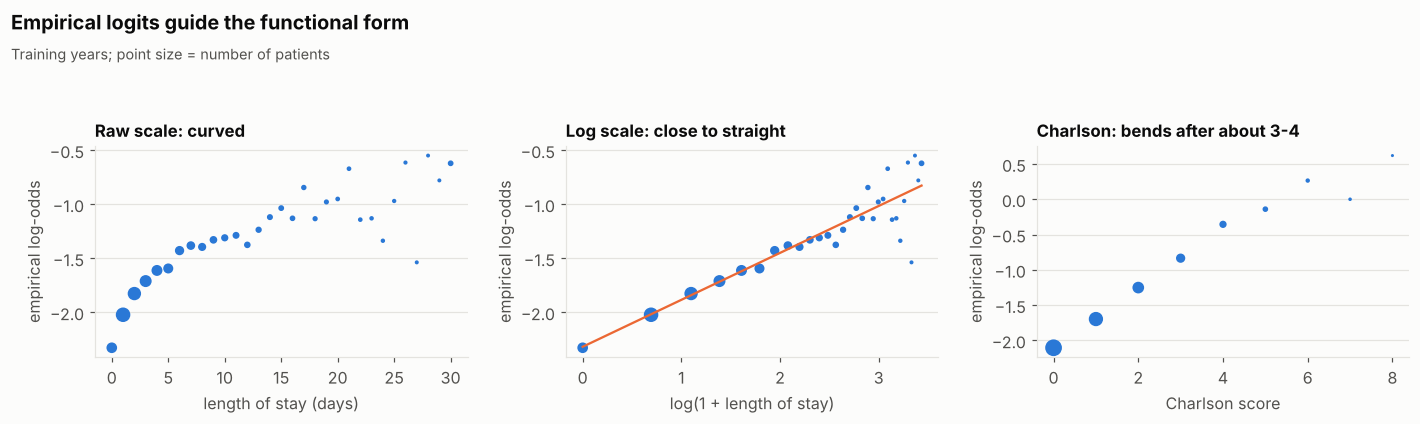

In [2]:
def emp_logit(x, cap):
    g = train.assign(x=train[x].clip(upper=cap)).groupby("x")["readmit_30d"].agg(["sum", "size"])
    return np.log((g["sum"] + 0.5) / (g["size"] - g["sum"] + 0.5)), g["size"]


fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
el, n = emp_logit("los_days", 30)
axes[0].scatter(el.index, el, s=np.sqrt(n) / 3, color=viz.BLUE)
axes[0].set_xlabel("length of stay (days)")
axes[0].set_title("Raw scale: curved", fontsize=11, pad=6)
axes[1].scatter(np.log1p(el.index), el, s=np.sqrt(n) / 3, color=viz.BLUE)
b = np.polyfit(np.log1p(el.index), el, 1, w=np.sqrt(n))
xx = np.linspace(0, np.log1p(30), 50)
axes[1].plot(xx, np.polyval(b, xx), color=viz.ORANGE, lw=1.5)
axes[1].set_xlabel("log(1 + length of stay)")
axes[1].set_title("Log scale: close to straight", fontsize=11, pad=6)
el, n = emp_logit("charlson", 8)
axes[2].scatter(el.index, el, s=np.sqrt(n) / 3, color=viz.BLUE)
axes[2].set_xlabel("Charlson score")
axes[2].set_title("Charlson: bends after about 3-4", fontsize=11, pad=6)
for ax in axes:
    ax.set_ylabel("empirical log-odds")
viz.fig_title(fig, "Empirical logits guide the functional form", "Training years; point size = number of patients")
viz.save(fig, "05_empirical_logits")
fig

Length of stay is curved on the raw scale but nearly straight on a log scale; the Charlson score
rises then bends. These two plots motivate the champion model's `log1p` transforms and a spline.
(The crude Charlson curve also mixes in age and length of stay, which is why we confirm the
choice with likelihood-ratio tests below rather than by eye.)

## 2. Maximum likelihood from scratch, checked against statsmodels

In [3]:
yb, Xb = dmatrices(f"readmit_30d ~ {P.BASELINE_FORMULA}", train, return_type="dataframe")
mine = fit_logit(Xb.to_numpy(), yb.to_numpy().ravel(), names=list(Xb.columns))
ref = sm.Logit(yb, Xb).fit(disp=0)
print(f"Newton-Raphson converged in {mine.n_iter} iterations; "
      f"max |coef diff| = {np.max(np.abs(mine.params - ref.params.to_numpy())):.1e}; "
      f"max |SE diff| = {np.max(np.abs(mine.bse - ref.bse.to_numpy())):.1e}; "
      f"log-likelihood {mine.loglik:,.2f} vs {ref.llf:,.2f}")

Newton-Raphson converged in 6 iterations; max |coef diff| = 1.5e-15; max |SE diff| = 3.6e-14; log-likelihood -61,424.08 vs -61,424.08


**Gradient descent** reaches the same answer far more slowly. It is how logistic regression is
trained inside neural networks, and why feature **scaling** matters there (Newton's method does
not care).

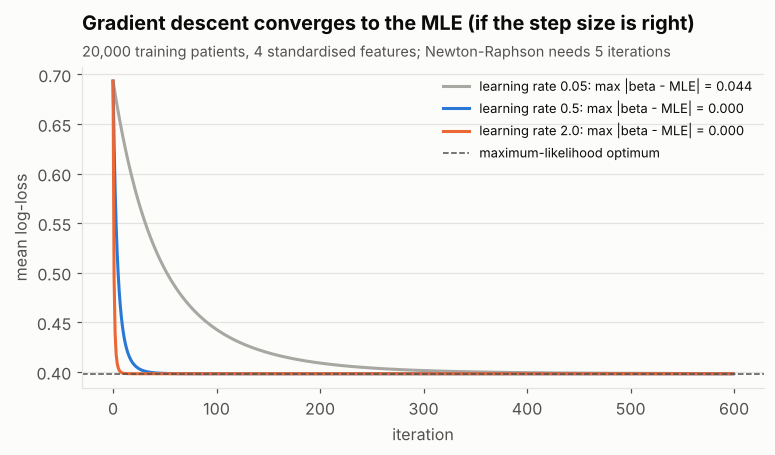

In [4]:
sub = train.sample(20_000, random_state=0)
Xs = np.column_stack([np.ones(len(sub)), StandardScaler().fit_transform(sub[["los_days", "charlson", "prior_ed_6m", "age"]])])
ys = sub["readmit_30d"].to_numpy()
mle = fit_logit(Xs, ys)
fig, ax = plt.subplots(figsize=(8, 3.8))
for lr, col in [(0.05, viz.GREY), (0.5, viz.BLUE), (2.0, viz.ORANGE)]:
    beta, hist = gradient_descent(Xs, ys, lr=lr, n_iter=600)
    ax.plot(hist, color=col, label=f"learning rate {lr}: max |beta - MLE| = {np.max(np.abs(beta - mle.params)):.3f}")
ax.axhline(-mle.loglik / len(ys), color=viz.TEXT_2, ls="--", lw=1, label="maximum-likelihood optimum")
ax.set_xlabel("iteration")
ax.set_ylabel("mean log-loss")
ax.legend(fontsize=8.5)
ax.set_title("Gradient descent converges to the MLE (if the step size is right)")
viz.subtitle(ax, "20,000 training patients, 4 standardised features; Newton-Raphson needs 5 iterations")
viz.save(fig, "05_gradient_descent")
fig

## 3. Model building: from a naive baseline to the champion

In [5]:
ladder = {
    "A baseline (all linear)": P.BASELINE_FORMULA,
    "B + log transforms": P.BASELINE_FORMULA.replace("los_days", "np.log1p(los_days)")
        .replace("prior_adm_12m", "np.log1p(prior_adm_12m)").replace("prior_ed_6m", "np.minimum(prior_ed_6m, 6)"),
}
ladder["C + Charlson spline"] = ladder["B + log transforms"].replace(
    "charlson", "bs(charlson_c, knots=[2], degree=2, lower_bound=0, upper_bound=9)")
ladder["D + Charlson x under-75"] = ladder["C + Charlson spline"] + " + charlson_c:under75"
ladder["E champion (drop noise)"] = P.CHAMPION_FORMULA
fits = {k: P.fit(train, f) for k, f in ladder.items()}
tbl = pd.DataFrame({k: {"params": len(r.params), "log-lik": r.llf, "AIC": r.aic, "BIC": r.bic} for k, r in fits.items()}).T
tbl["dAIC vs previous"] = tbl["AIC"].diff()
tbl.style.format({"log-lik": "{:,.1f}", "AIC": "{:,.1f}", "BIC": "{:,.1f}", "dAIC vs previous": "{:+.1f}", "params": "{:.0f}"})

,params,log-lik,AIC,BIC,dAIC vs previous
A baseline (all linear),19,"-61,424.1","122,886.2","123,075.5",+nan
B + log transforms,19,"-61,241.6","122,521.2","122,710.5",-365.0
C + Charlson spline,21,"-61,228.8","122,499.6","122,708.9",-21.6
D + Charlson x under-75,22,"-61,218.5","122,481.0","122,700.2",-18.6
E champion (drop noise),20,"-61,219.8","122,479.6","122,678.9",-1.4


In [6]:
def lr_test(small, big):
    lr = 2 * (big.llf - small.llf)
    df = len(big.params) - len(small.params)
    from scipy import stats
    return lr, df, stats.chi2.sf(lr, abs(df))


rows = {
    "Charlson x under-75 interaction (C vs D)": lr_test(fits["C + Charlson spline"], fits["D + Charlson x under-75"]),
    "noise variables jointly (E vs D)": lr_test(fits["E champion (drop noise)"], fits["D + Charlson x under-75"]),
}
pd.DataFrame(rows, index=["LR statistic", "df", "p-value"]).T.style.format({"LR statistic": "{:.2f}", "df": "{:.0f}", "p-value": "{:.3g}"})

,LR statistic,df,p-value
Charlson x under-75 interaction (C vs D),20.64,1,5.55e-06
noise variables jointly (E vs D),2.64,2,0.267


* **Log transforms** (B) and the **spline** (C) each reduce AIC: better functional form.
* The **interaction** is supported by a likelihood-ratio test.
* The two **noise variables** are jointly insignificant, so the champion drops them; BIC, which
  penalises parameters more heavily, agrees.

### Wald vs likelihood-ratio
Statsmodels' summary shows **Wald** tests (coefficient / SE). They rely on a quadratic
approximation of the log-likelihood at the estimate; the LR test compares the two fitted
likelihoods directly and is preferred when they disagree. Here, with a big sample, they agree:

In [7]:
d = fits["D + Charlson x under-75"]
print(f"interaction: Wald z^2 = {(d.params['charlson_c:under75'] / d.bse['charlson_c:under75']) ** 2:.2f}  vs  "
      f"LR = {rows['Charlson x under-75 interaction (C vs D)'][0]:.2f}")

interaction: Wald z^2 = 20.79  vs  LR = 20.64


## 4. Did we recover the truth?
The synthetic cohort lets us do something real data never allows: compare estimates with the
known data-generating effects.

In [8]:
champ = fits["E champion (drop noise)"]
ci = champ.conf_int()
rec = pd.DataFrame({
    "true": [TRUE_EFFECTS[k] for k in ["log_los", "emergency", "prior_ed_6m", "log_prior_adm_12m", "care_home",
                                       "polypharmacy", "medical_specialty", "weekend_discharge", "charlson_x_under75"]],
    "estimate": champ.params[["np.log1p(los_days)", "emergency", "np.minimum(prior_ed_6m, 6)", "np.log1p(prior_adm_12m)",
                              "care_home", "polypharmacy", "medical_specialty", "weekend_discharge", "charlson_c:under75"]].to_numpy(),
}, index=["log(1+LOS)", "emergency admission", "A&E visits (capped 6)", "log(1+prior admissions)", "care home",
          "polypharmacy", "medical specialty", "weekend discharge", "Charlson x under-75"])
names = ["np.log1p(los_days)", "emergency", "np.minimum(prior_ed_6m, 6)", "np.log1p(prior_adm_12m)", "care_home",
         "polypharmacy", "medical_specialty", "weekend_discharge", "charlson_c:under75"]
rec["95% CI low"] = ci.loc[names, 0].to_numpy()
rec["95% CI high"] = ci.loc[names, 1].to_numpy()
rec["covers truth"] = (rec["95% CI low"] <= rec["true"]) & (rec["true"] <= rec["95% CI high"])
rec["odds ratio"] = np.exp(rec["estimate"])
rec.round(3)

,true,estimate,95% CI low,95% CI high,covers truth,odds ratio
log(1+LOS),0.35,0.345,0.323,0.367,True,1.412
emergency admission,0.60,0.602,0.568,0.636,True,1.826
A&E visits (capped 6),0.17,0.179,0.167,0.191,True,1.196
log(1+prior admissions),0.50,0.521,0.485,0.557,True,1.684
care home,0.35,0.318,0.243,0.392,True,1.374
polypharmacy,0.25,0.261,0.217,0.305,True,1.298
medical specialty,0.20,0.183,0.153,0.213,True,1.201
weekend discharge,0.08,0.088,0.055,0.122,True,1.093
Charlson x under-75,0.05,0.079,0.045,0.112,True,1.082


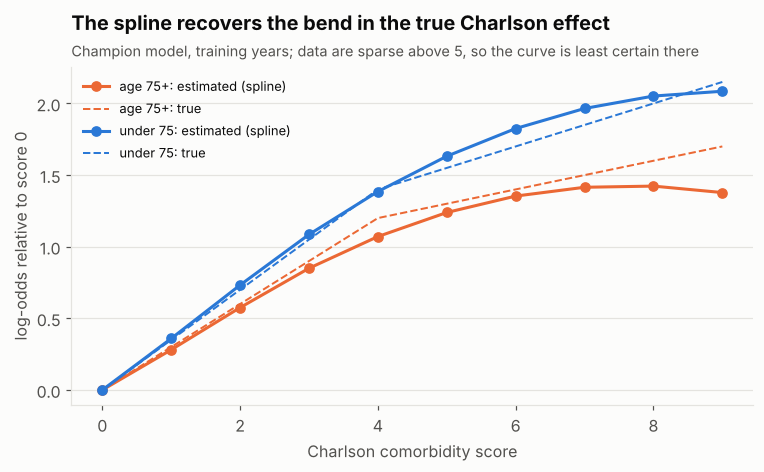

In [9]:
champ_saved = P.to_saved(champ, "champion", P.CHAMPION_FORMULA, len(train))
grid = pd.DataFrame({"charlson": np.arange(0, 10)})
fig, ax = plt.subplots(figsize=(8, 4))
for under, col, lab in [(0, viz.ORANGE, "age 75+"), (1, viz.BLUE, "under 75")]:
    g = cohort.iloc[[0] * 10].copy().reset_index(drop=True)
    g["charlson"] = grid["charlson"]
    g["age"] = 80 if under == 0 else 50
    g["age_band"] = "75+" if under == 0 else "16-74"
    X = champ_saved.design(g)  # same design as the fitted model, via the saved formula
    lp = X.to_numpy() @ champ.params.to_numpy()
    est = lp - lp[0]
    c = grid["charlson"].to_numpy()
    truth = TRUE_EFFECTS["charlson_le4"] * np.minimum(c, 4) + TRUE_EFFECTS["charlson_gt4"] * np.maximum(c - 4, 0) \
        + TRUE_EFFECTS["charlson_x_under75"] * c * under
    ax.plot(c, est, color=col, marker="o", label=f"{lab}: estimated (spline)")
    ax.plot(c, truth, color=col, ls="--", lw=1.3, label=f"{lab}: true")
ax.set_xlabel("Charlson comorbidity score")
ax.set_ylabel("log-odds relative to score 0")
ax.legend(fontsize=8.5)
ax.set_title("The spline recovers the bend in the true Charlson effect")
viz.subtitle(ax, "Champion model, training years; data are sparse above 5, so the curve is least certain there")
viz.save(fig, "05_charlson_spline")
fig

## 5. Collinearity: variance inflation factors

In [10]:
_, Xd = dmatrices(f"readmit_30d ~ {P.BASELINE_FORMULA}", train, return_type="dataframe")
vif = pd.Series([variance_inflation_factor(Xd.to_numpy(), i) for i in range(1, Xd.shape[1])], index=Xd.columns[1:])
vif.sort_values(ascending=False).round(2).head(8).to_frame("VIF")

,VIF
C(imd)[T.2],1.48
C(imd)[T.4],1.47
C(imd)[T.3],1.47
C(imd)[T.5],1.47
C(age_band)[T.75+],1.46
charlson,1.39
polypharmacy,1.17
prior_adm_12m,1.15


All VIFs are low (well under 5): the predictors are correlated, as clinical features are, but not
enough to make individual coefficients unstable.

## 6. Confounding: what happens to deprivation?

In [11]:
demo = P.fit(train, "C(age_band) + sex + C(imd)")
cmp = pd.DataFrame({"demographics only": np.exp(demo.params.filter(like="imd")),
                    "with clinical features": np.exp(champ.params.filter(like="imd"))}).round(3)
cmp.index = [f"IMD {i} vs 1 (most deprived)" for i in range(2, 6)]
cmp

,demographics only,with clinical features
IMD 2 vs 1 (most deprived),0.924,0.998
IMD 3 vs 1 (most deprived),0.883,1.032
IMD 4 vs 1 (most deprived),0.846,1.063
IMD 5 vs 1 (most deprived),0.815,1.105


With demographics alone, less deprived quintiles have **lower** odds of readmission (as in the real
NHS data in notebook 02). Once clinical features are added, the pattern flattens and even
reverses. In this cohort, deprivation raises risk *through* comorbidity, prior A&E use and longer
stays. Its coefficient in the full model is a direct effect given those features, not the total
effect. Which one you want depends on the question: for predicting an individual's risk, the
full model; for describing inequality, the total effect.

## 7. Regularisation: L1, L2 and elastic net

With many candidate features (here: all main effects plus every pairwise interaction among the
clinical variables, about 80 columns), penalised likelihood guards against overfitting:

$$\hat\beta = \arg\max_\beta \; \ell(\beta) - \lambda\Big(\alpha\|\beta\|_1 + \tfrac{1-\alpha}{2}\|\beta\|_2^2\Big).$$

L1 (lasso) sets some coefficients exactly to zero; L2 (ridge) shrinks all of them; elastic net
mixes the two. Features must be standardised first so the penalty treats them equally.

In [12]:
clin = ["np.log1p(los_days)", "emergency", "charlson", "np.minimum(prior_ed_6m, 6)", "np.log1p(prior_adm_12m)",
        "care_home", "polypharmacy", "medical_specialty", "weekend_discharge", "ward_occupancy", "discharge_hour", "age"]
big_formula = "(" + " + ".join(clin) + ") ** 2 + C(imd) + sex"
sub40 = train.sample(40_000, random_state=1)  # subsample keeps this section quick
ysub = sub40["readmit_30d"].to_numpy()
_, Xbig = dmatrices(f"readmit_30d ~ {big_formula}", sub40, return_type="dataframe")
Xbig = Xbig.drop(columns="Intercept")
scaler = StandardScaler().fit(Xbig)
Z = scaler.transform(Xbig)
print(f"expanded design: {Z.shape[1]} features")

cv = StratifiedKFold(3, shuffle=True, random_state=0)
cands = {
    "unpenalised (all ~80 features)": LogisticRegression(C=1e6, max_iter=3000),
    "L2 ridge, C=0.01": LogisticRegression(l1_ratio=0, C=0.01, max_iter=3000),
    "L1 lasso, C=0.005": LogisticRegression(l1_ratio=1, C=0.005, solver="liblinear"),
    "elastic net (a=0.5), C=0.01": LogisticRegression(l1_ratio=0.5, C=0.01, solver="saga", max_iter=500, tol=1e-3),
}
res = {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for name, m in cands.items():
        ll = -cross_val_score(m, Z, ysub, cv=cv, scoring="neg_log_loss").mean()
        auc = cross_val_score(m, Z, ysub, cv=cv, scoring="roc_auc").mean()
        nz = int((np.abs(m.fit(Z, ysub).coef_) > 1e-8).sum())
        res[name] = {"CV log-loss": ll, "CV AUC": auc, "non-zero coefs": nz}
_, Xc = dmatrices(f"readmit_30d ~ {P.CHAMPION_FORMULA}", sub40, return_type="dataframe")
champ_cv = LogisticRegression(C=1e6, max_iter=3000)
Zc = StandardScaler().fit_transform(Xc.drop(columns="Intercept"))
res["champion (hand-built, 19 terms)"] = {
    "CV log-loss": -cross_val_score(champ_cv, Zc, ysub, cv=cv, scoring="neg_log_loss").mean(),
    "CV AUC": cross_val_score(champ_cv, Zc, ysub, cv=cv, scoring="roc_auc").mean(), "non-zero coefs": Zc.shape[1]}
pd.DataFrame(res).T.style.format({"CV log-loss": "{:.5f}", "CV AUC": "{:.4f}", "non-zero coefs": "{:.0f}"})

expanded design: 83 features


,CV log-loss,CV AUC,non-zero coefs
unpenalised (all ~80 features),0.38882,0.6676,83
"L2 ridge, C=0.01",0.38814,0.6697,83
"L1 lasso, C=0.005",0.39077,0.6631,25
"elastic net (a=0.5), C=0.01",0.38809,0.6704,39
"champion (hand-built, 19 terms)",0.38649,0.6747,19


(3-fold cross-validation on a 40,000-patient training subsample, to keep the notebook quick.)

Three lessons:

* Ridge and elastic net improve a little on the unpenalised 83-term model: some overfitting is
  being controlled even with 40,000 patients.
* The lasso at this penalty keeps 25 terms but shrinks too hard and loses some accuracy; its
  penalty would normally be tuned by cross-validation (`LogisticRegressionCV`).
* The **hand-built 19-term champion beats all of them**. Getting the functional form right
  (log transforms, a spline, one clinically motivated interaction) does more than throwing every
  pairwise interaction at a penalty.

first 6 features to enter: ['log1p(los_days):charlson', 'emergency:charlson', 'charlson:log1p(prior_adm_12m)', 'log1p(los_days):minimum(prior_ed_6m, 6)', 'log1p(los_days):log1p(prior_adm_12m)', 'emergency:log1p(prior_adm_12m)']
     C  terms selected  of which involve a noise variable
0.0001               0                                  0
0.0002               0                                  0
0.0007               7                                  0
0.0025              15                                  1
0.0086              30                                  7
0.0293              40                                  9
0.1000              60                                 14


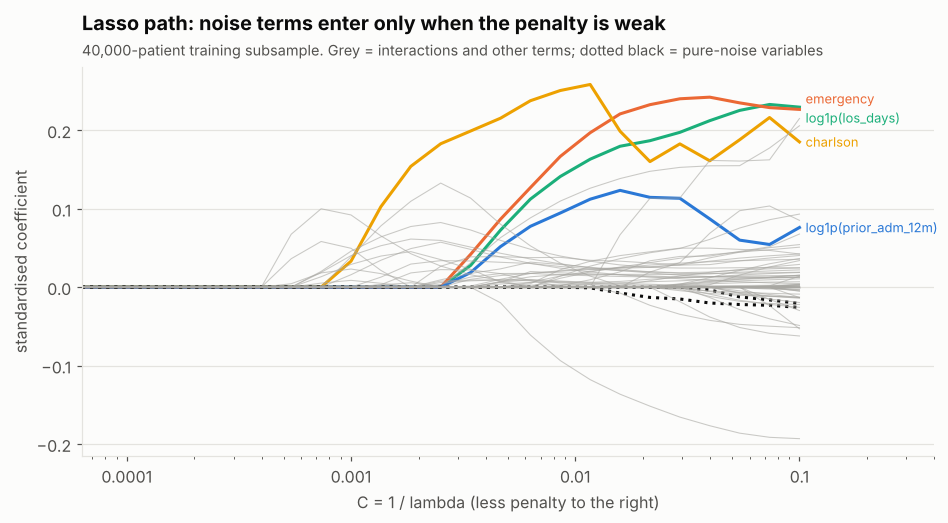

In [13]:
Cs = np.logspace(-4.2, -1, 25)
path = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for C in Cs:
        path.append(LogisticRegression(l1_ratio=1, C=C, solver="liblinear").fit(Z, ysub).coef_.ravel())
path = pd.DataFrame(path, index=Cs, columns=Xbig.columns)
first = (path.abs() > 1e-8).idxmax().where((path.abs() > 1e-8).any())
order = first.dropna().sort_values()  # smallest C = strongest penalty = entered first

fig, ax = plt.subplots(figsize=(10, 4.6))
highlight = {"emergency": viz.ORANGE, "np.log1p(prior_adm_12m)": viz.BLUE, "np.log1p(los_days)": viz.AQUA,
             "charlson": viz.YELLOW, "ward_occupancy": viz.TEXT, "discharge_hour": viz.TEXT}
for c in path.columns:
    ax.plot(path.index, path[c], color=highlight.get(c, viz.GREY), lw=2 if c in highlight else 0.7,
            ls=":" if c in {"ward_occupancy", "discharge_hour"} else "-", alpha=1 if c in highlight else 0.6)
for c, col in highlight.items():
    if c in {"ward_occupancy", "discharge_hour"}:
        continue
    nudge = {"emergency": 7, "np.log1p(los_days)": -7}.get(c, 0)  # keep neighbouring labels apart
    ax.annotate(c.replace("np.", ""), (Cs[-1], path[c].iloc[-1]), xytext=(4, nudge), textcoords="offset points",
                fontsize=8.5, color=col, va="center")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlabel("C = 1 / lambda (less penalty to the right)")
ax.set_ylabel("standardised coefficient")
ax.set_xlim(Cs[0], Cs[-1] * 4)
ax.set_title("Lasso path: noise terms enter only when the penalty is weak")
viz.subtitle(ax, "40,000-patient training subsample. Grey = interactions and other terms; dotted black = pure-noise variables")
viz.save(fig, "05_lasso_path")
print("first 6 features to enter:", [c.replace("np.", "") for c in order.index[:6]])
noise_cols = [c for c in path.columns if "ward_occupancy" in c or "discharge_hour" in c]
entry = pd.DataFrame({"C": Cs, "terms selected": (path.abs() > 1e-8).sum(axis=1).to_numpy(),
                      "of which involve a noise variable": (path[noise_cols].abs() > 1e-8).sum(axis=1).to_numpy()})
print(entry.iloc[::4].to_string(index=False, float_format=lambda v: f"{v:.4f}"))
fig

With a strong penalty the lasso keeps only real signal; as the penalty weakens it starts admitting
noise terms (mostly interactions involving the two noise variables). That is the bias-variance
trade-off made visible, and why the penalty strength is chosen by cross-validation.

The path also shows a known weakness of the lasso. The first terms to enter are **products** of
strong predictors (for example length of stay x Charlson), which are highly correlated with the
main effects and can stand in for them. Among correlated features, the lasso's choice is somewhat
arbitrary, so lasso selection is a screening aid, not a substitute for clinical reasoning.

## 8. Class imbalance: re-weighting fixes nothing that needed fixing

About 15% of discharges are readmitted. A common reflex is to re-weight or re-sample to 50/50.
For logistic regression that changes **only the intercept** (by the log of the weight ratio), so
ranking (AUC) is unchanged and the probabilities become badly inflated.

In [14]:
w = np.where(y == 1, (1 - y.mean()) / y.mean(), 1.0)
bal = P.fit_weighted(train, P.CHAMPION_FORMULA, w)
p_un = champ.predict(train)
p_bal = bal.predict(train)
shift = np.log(w.max())
p_fix = sigmoid(np.log(p_bal / (1 - p_bal)) - shift)
pd.DataFrame({
    "unweighted": [M.auc(y, p_un), p_un.mean(), y.mean(), M.brier(y, p_un)],
    "class-balanced weights": [M.auc(y, p_bal), p_bal.mean(), y.mean(), M.brier(y, p_bal)],
    "balanced + intercept correction": [M.auc(y, p_fix), p_fix.mean(), y.mean(), M.brier(y, p_fix)],
}, index=["AUC", "mean predicted risk", "observed rate", "Brier score"]).round(4)

,unweighted,class-balanced weights,balanced + intercept correction
AUC,0.6756,0.6756,0.6756
mean predicted risk,0.1463,0.4660,0.1463
observed rate,0.1463,0.1463,0.1463
Brier score,0.1172,0.2240,0.1172


Same AUC, but balanced weights predict an average risk of about 47% against an observed 15%.
Subtracting log(weight ratio) from the intercept (King and Zeng's prior correction) recovers
calibrated probabilities. Imbalance is a **threshold** question (notebook 06), not a fitting problem.

## 9. Separation: when maximum likelihood breaks

If a predictor perfectly separates outcomes, the MLE does not exist: the coefficient runs off to
infinity. This happens with rare categories in small samples (one small hospital, one rare
procedure). A small ridge penalty (or Firth's method) gives a finite, sensible answer.

In [15]:
rng = np.random.default_rng(5)
n = 300
x_rare = np.zeros(n)
x_rare[:6] = 1
yy = rng.binomial(1, 0.15, n).astype(float)
yy[:6] = 1  # every patient with the rare flag was readmitted
Xsep = np.column_stack([np.ones(n), x_rare, rng.normal(size=n)])
growth = {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for it in [5, 10, 20, 40]:
        growth[f"after {it} Newton steps"] = fit_logit(Xsep, yy, max_iter=it, tol=0).params[1]
    glm = sm.GLM(yy, Xsep, family=sm.families.Binomial()).fit()
ridge = fit_logit(Xsep, yy, l2=1.0)
print("unpenalised rare-flag coefficient keeps growing:", {k: round(v, 1) for k, v in growth.items()})
print(f"statsmodels GLM: coefficient {glm.params[1]:.1f}, SE {glm.bse[1]:,.0f}  (meaningless: the MLE is at infinity)")
print(f"ridge (lambda=1): coefficient {ridge.params[1]:.2f} (SE {ridge.bse[1]:.2f}), odds ratio {np.exp(ridge.params[1]):.1f}")

unpenalised rare-flag coefficient keeps growing: {'after 5 Newton steps': np.float64(9.9), 'after 10 Newton steps': np.float64(14.9), 'after 20 Newton steps': np.float64(24.9), 'after 40 Newton steps': np.float64(34.9)}
statsmodels GLM: coefficient 23.3, SE 11,931  (meaningless: the MLE is at infinity)
ridge (lambda=1): coefficient 2.20 (SE 0.65), odds ratio 9.0


## 10. Save the models
Models are saved as plain JSON (formula + coefficients), so they can be reviewed in a pull
request and scored without unpickling anything.

In [16]:
lace_fit = P.fit(train, P.LACE_FORMULA)
saved = {
    "champion": P.to_saved(champ, "champion", P.CHAMPION_FORMULA, len(train)),
    "baseline": P.to_saved(fits["A baseline (all linear)"], "baseline", P.BASELINE_FORMULA, len(train)),
    "lace": P.to_saved(lace_fit, "lace", P.LACE_FORMULA, len(train)),
}
for s in saved.values():
    print("saved", s.save().name, f"({len(s.params)} coefficients)")
print(f"LACE logistic: log-odds per LACE point = {lace_fit.params['lace']:.3f} (odds ratio {np.exp(lace_fit.params['lace']):.2f})")

saved champion.json (20 coefficients)
saved baseline.json (19 coefficients)
saved lace.json (2 coefficients)
LACE logistic: log-odds per LACE point = 0.192 (odds ratio 1.21)


**Takeaways**

* Our Newton-Raphson implementation matches statsmodels to machine precision; gradient descent
  gets there too, with the right step size.
* Functional form matters: log transforms and a Charlson spline beat raw linear terms, chosen by
  empirical logits, AIC and likelihood-ratio tests.
* Estimated effects match the known truth, and the noise variables are rejected by LR tests and
  left out by the lasso.
* Re-weighting for imbalance breaks calibration without improving ranking; separation needs a
  penalty.